# Polygonal hysteresis model

The branch $f$ linearly interpolates the normalized magnetization values $y_i$ at $N$ equally spaced field points $x_i$ on $[-1,1]$, with $h_i=2/(N-1)$.
Saturation fixes $y_i=-1$ for $x_i\le -w_{\mathrm L}$ and $y_i=1$ for $x_i\ge w_{\mathrm R}$.
The free $y_i$ minimize $E(\mathbf{y})$.

$$
E(\mathbf{y}) =
         \underbrace{\frac{A}{2}\sum_{i=1}^{N-1} h_i \left[\frac{y_{i+1}-y_i}{h_i}\right]^2}_{\text{slope\;penalty}} 
       + \underbrace{\frac{B}{2}\sum_{i=2}^{N-1} \bar h_i \left[\frac{1}{h_i}\left(\frac{y_{i+1}-y_i}{h_i}-\frac{y_{i}-y_{i-1}}{h_{i-1}}\right)\right]^2}_{\text{curvature\;penalty}}
       + \underbrace{\frac{1}{2}\sum_{j=1}^{n} K_j[f(x_j^{\mathrm a})-y_j^{\mathrm a}]^2}_{\text{anchors\; points}},
       \qquad n\geq 0,\quad -w_{\mathrm L}<x_j^{\mathrm a}<w_{\mathrm R}
$$

- `smoothness_weights=[A, B]` sets the weights of the slope and curvature terms in that order, with $A,B\ge 0$ and $A+B>0$.
- Each optional `anchorpoints` row `[x, y, K]` gives a field coordinate $x$, a target $y$, and a nonnegative gain $K$. The gain weights the squared deviation of the linearly interpolated $f(x)$ from $y$.
- `apply_sine=True` maps each optimized value $y_i$ to $\sin(\pi y_i/2)$ after minimization.
- `apply_mirror=True` appends the point-reflected samples $(-x_i,-y_i)$ to form the descending branch after any sine mapping.

In [ ]:
import polygon_hysteresis_modeller as phm

import mammos_analysis as ma
import mammos_entity as me

import numpy as np

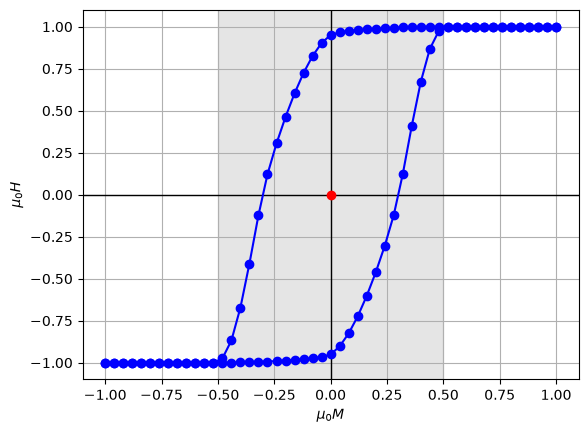

In [ ]:
Xc = [-0.3, 0.0, 10000]  # coercivity anchor (x, y, gain)
Yr = [0.0, 0.8, 10000]   # remanence anchor (x, y, gain)

saturation_bounds = [0.5, 0.5]
smoothness_weights = [1.0, 1e-3]

x, y = phm.generate_polygon(
    points_per_branch=51,
    smoothness_weights=smoothness_weights,
    saturation_bounds=saturation_bounds,
    anchorpoints=[Xc, Yr],
    apply_sine=True, 
    apply_mirror=True,
)

phm.plot_curve(x, y, np.array(saturation_bounds), 0, 0)